# 오류와 읽기 쓰기 분리

**이 노트북에서 할 일**

1. 없는 주문을 찾던 도구가 오류를 내면, 모델과 주고받던 흐름이 어떻게 되는지 봅니다.
2. 도구 오류를 도구 메시지에 담아 모델에게 보내고, 모델이 도구 없이 답하는지 봅니다.
3. 쓰기 도구를 사람 확인 뒤에만 목록에 넣어, 모델이 고를 수 있는 도구를 나눕니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 모델 요청은 모두 8~9번입니다.
6절에서 2번, 7절에서 4번, 8절에서 2~3번을 보냅니다.
요금표로 센 예상 비용은 모두 합쳐 0.01달러 아래이고, 청구 금액이 아닙니다.

도구는 둘입니다.
읽기 도구는 실습 폴더의 주문 CSV를 읽기만 합니다.
쓰기 도구는 이 절에서 만든 흉내라 아무 파일도 바꾸지 않습니다.
앞 절 함수와 Ch 6 06절 함수는 도구 파일 `order_tools.py`에서 가져옵니다.
교재 출력을 만든 실행에서는 노트북 전체가 10초 안에 끝났습니다.

**기준 버전** — 첫 셀에서 패키지 다섯을 설치합니다.
판은 langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
pandas 3.0.5와 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~7절을 읽습니다.
두 도구를 만들고, 05절 방식(Before)과 고친 방식(After)을 견주는 자리입니다.
8~9절은 사람 확인 값을 바꿔 보고 요청 수를 세는 자리이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch19-model-tools`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 한 줄로 이어지는 그림으로 파란 상자 확인 전 목록 pick_tools 사람 확인 False 읽기 도구 하나 get_order_by_id에서 시작해 보라 상자 gpt-5.4-mini 요청 1 O999 주문의 금액을 알려 줘, 노란 상자 도구 호출 요청 get_order_by_id O999, 회색 상자 ToolException 오류 담기 설정 True, 노란 상자 도구 메시지 결과 상태 error 내용 오류 글, 보라 상자 gpt-5.4-mini 요청 2 질문 첫 응답 도구 메시지를 차례로 거쳐 노란 상자 최종 답 도구 호출 요청 0건 답 글에 O999 있음으로 끝나는 그림](attachment:06-1-확인-전-목록과-오류-메시지.png)

위에서 아래로 읽습니다.
맨 위 파란 상자는 사람 확인 전이라 읽기 도구만 담은 목록입니다.
노란 도구 호출 요청이 회색 상자에서 도구 오류를 만나고, 오류 담기 설정이 켜져 있어 도구 메시지가 됩니다.
보라 모델은 그 도구 메시지를 받고 도구 없이 최종 답을 적습니다.
노란 상자는 노트북 7절 출력입니다.
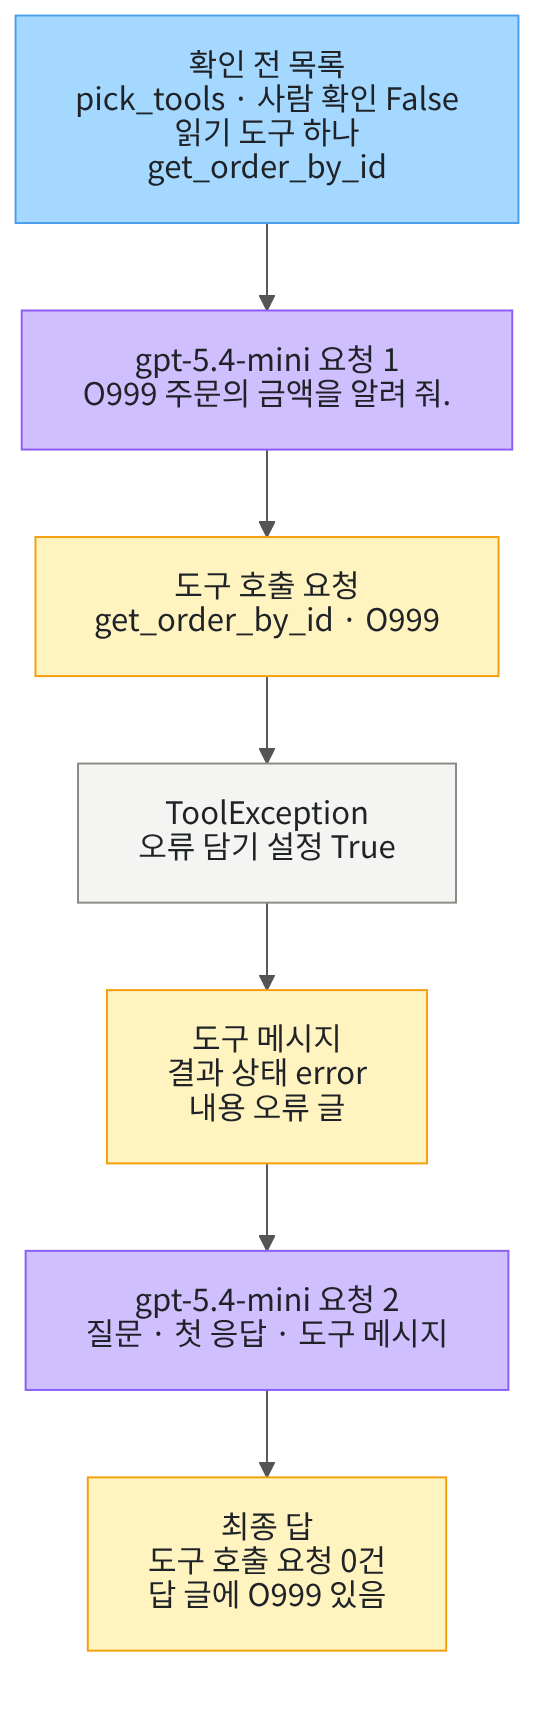

## 1. 준비

05절에서는 모델이 적어 보낸 도구 호출 요청을 프로그램이 실행하고, 도구 메시지를 모델에게 보냈습니다.
그 절의 도구는 있는 주문만 찾았고, 주문을 읽기만 했습니다.
이 절은 도구가 일을 끝내지 못하는 경우와, 무언가를 바꾸는 도구를 다룹니다.

첫 셀은 패키지 다섯 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-core==1.6.2" "langchain-openai==1.6.0" "pandas==3.0.5" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("pandas:", version("pandas"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
pandas: 3.0.5
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`·`langchain-core: 1.6.2`·`langchain-openai: 1.6.0`이 보입니다.
출력 줄 `pandas: 3.0.5`와 `python-dotenv: 1.2.3`도 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-24에 이 판으로 실행한 결과입니다.

앞에서 배운 함수는 `order_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
오류 이름 `ToolException`은 LangChain이 도구 오류에 쓰는 이름이고, 이 절에서 처음 씁니다.
도구 파일에서는 03절 몸통 함수 `find_order`와 04·05절 함수 넷을 가져옵니다.
Ch 6 06절 함수 `estimate_cost`도 함께 가져옵니다.

In [2]:
# 모델·도구·도구 오류·메시지를 만드는 이름과 도구 파일의 함수 여섯을 가져옵니다
import os

from langchain.chat_models import init_chat_model
from langchain.tools import ToolException, tool
from langchain_core.messages import HumanMessage

from order_tools import ask_until_answer, estimate_cost, find_order, run_tool_calls, sum_usage, tool_call_names

print("가져온 이름:", "os", "init_chat_model", "ToolException", "tool", "HumanMessage")

가져온 이름: os init_chat_model ToolException tool HumanMessage


**결과 읽기** — 출력 줄에 가져온 이름 다섯이 보입니다.
도구 파일에서 가져온 함수 여섯은 셀의 `from order_tools import …` 줄에 적혀 있습니다.
함수 `ask_until_answer`는 05절 값 바꿔 보기의 루프이고, 바퀴 한도까지 도구를 실행하며 다시 묻습니다.

다음 셀은 01~05절과 같은 방법으로 주문 CSV가 있는 프로젝트 맨 위 폴더를 찾습니다.
읽기 도구의 몸통이 이 CSV 파일을 읽습니다.

In [3]:
# 노트북을 어느 폴더에서 열어도 주문 CSV를 찾게 후보 세 곳을 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part5/ch19-model-tools/data/orders.csv"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."
# CSV 파일 위치는 노트북이 정해 두는 값입니다(모델이 고를 값이 아님)
csv_path = root_path + "/labs/part5/ch19-model-tools/data/orders.csv"

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위: .`은 교재 출력을 프로젝트 맨 위에서 실행했다는 뜻입니다.
교재 출력은 실행 도구에 도구 파일 폴더를 따로 알려 준 실행이라 `.`이 찍혔습니다.
노트북을 `notebooks/` 폴더에서 열면 이 줄에 `../../../..`가 찍힙니다.
셀 안의 안내 글은 실습 폴더 맨 위도 적었지만, 도구 파일을 가져오려면 `notebooks/` 폴더에서 열어야 합니다.

## 2. 키와 모델 준비

모델은 04·05절과 같은 `gpt-5.4-mini`이고, 과정의 같은 설정으로 부릅니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [4]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도, 모델이 고르는 도구가 매번 같다고 보장하지는 않습니다.

In [5]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-24에 이 모델로 실행한 결과입니다.

## 3. 읽기 도구와 도구 오류

이 절의 도구는 둘이고, 하나는 주문을 찾아 읽기만 합니다.
자료를 읽기만 하고 아무것도 바꾸지 않는 도구를 읽기 도구라고 부릅니다.
식당으로 치면 열린 창으로 음식을 내어 주기만 하는 일입니다.

다음 셀은 05절의 한 건 도구를 고쳐 읽기 도구로 만듭니다.
설명은 03절 자세한 판과 같고, 넷째 문장 끝만 「없으면 오류를 냅니다」로 바꿨습니다.
찾지 못하면 None 대신 오류를 내고, 오류 이름으로 `ToolException`을 씁니다.
Ch 16 01절에서 `raise`로 오류를 일부러 낸 것과 같은 모양입니다.

In [6]:
# 주문 한 건을 찾는 읽기 도구를 만들고, 없는 주문이면 도구 오류를 냅니다
@tool
def get_order_by_id(order_id: str):
    """주문 번호로 주문 한 건을 찾습니다. 질문에 O103 같은 주문 번호가 있을 때 씁니다. 인자 order_id는 찾을 주문 번호입니다. 그 주문 한 줄을 딕셔너리로 내놓고, 없으면 오류를 냅니다."""
    order = find_order(csv_path, order_id)
    # 찾지 못하면 None 대신 도구 오류를 내서, 무엇이 잘못됐는지 글로 알립니다
    if order is None:
        raise ToolException("주문 번호 " + order_id + "에 맞는 주문이 없습니다. 주문 번호를 다시 확인해 주세요.")
    return order

**결과 읽기** — 정의 셀이라 출력이 없습니다.
도구 이름은 05절과 같은 `get_order_by_id`입니다.
몸통은 도구 파일의 `find_order`로 주문을 찾고, 찾지 못하면 `raise` 줄로 오류를 냅니다.
오류 글에는 무엇이 잘못됐는지와 다음에 할 일을 함께 적었습니다.

다음 셀은 있는 주문 O101을 이 도구로 찾습니다.
도구 객체의 속성 `handle_tool_error`의 값도 함께 봅니다.

In [7]:
# 있는 주문 O101을 읽기 도구로 찾고, 오류 담기 설정의 기본값을 봅니다(모델 요청 없음)
found = get_order_by_id.invoke({"order_id": "O101"})
print("찾은 주문:", found)
print("오류 담기 설정(handle_tool_error):", get_order_by_id.handle_tool_error)

찾은 주문: {'order_id': 'O101', 'customer_id': 'C001', 'status': 'paid', 'amount': 32000}
오류 담기 설정(handle_tool_error): False


**결과 읽기** — 라벨 `찾은 주문:` 뒤 딕셔너리는 주문 O101 한 줄이고, 금액은 `32000`입니다.
출력 줄 `오류 담기 설정(handle_tool_error): False`는 이 속성의 기본값입니다.
이 속성은 도구 오류를 받아 도구 메시지에 담을지 정하고, 이 절에서는 오류 담기 설정이라고 부릅니다.
값이 `False`이면 도구 오류를 받지 않고 그대로 위로 올려 보냅니다.

다음 셀은 없는 주문 O999를 넣어 봅니다.
실행 전에 예상해 봅니다.
설정이 `False`이니 도구 오류가 셀까지 올라올 것입니다.
이 셀만 그 오류를 받아 출력하고, 셀은 끝까지 갑니다.

In [8]:
# 없는 주문 O999를 넣어 도구 오류가 올라오는지 봅니다(이 셀만 그 오류를 받아 출력합니다)
try:
    get_order_by_id.invoke({"order_id": "O999"})
except ToolException as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:", error)

받은 오류: ToolException
오류 글: 주문 번호 O999에 맞는 주문이 없습니다. 주문 번호를 다시 확인해 주세요.


**결과 읽기** — 출력 줄 `받은 오류: ToolException`처럼 도구 오류가 셀까지 올라왔습니다.
라벨 `오류 글:` 뒤 글은 몸통의 `raise` 줄에 적은 글 그대로입니다.
도구 오류(ToolException)는 도구가 일을 끝내지 못했다고 알리려고 몸통에서 내는 오류입니다.
식당으로 치면 주방이 재료가 없다고 알리는 일입니다.

오류를 받지 않는 실제 프로그램이라면 여기서 멈춥니다.
모델이 부른 도구가 이렇게 멈추면, 모델은 무엇이 잘못됐는지 듣지 못합니다.
그 장면은 6절에서 모델과 함께 봅니다.

## 4. 쓰기 도구와 사람 확인

둘째 도구는 주문 취소 요청을 등록합니다.
주문 상태처럼 무언가를 바꾸는 도구를 쓰기 도구라고 부릅니다.
Ch 17 02절에서 본 부작용이 있는 도구이고, 식당으로 치면 칼을 넣어 둔 서랍입니다.

다음 셀의 쓰기 도구는 이 절에서 만든 흉내입니다.
몸통은 받은 주문 번호를 딕셔너리에 적어 내놓기만 하고, CSV도 다른 파일도 바꾸지 않습니다.
실제 서비스라면 이 자리에서 주문 상태가 바뀝니다.

In [9]:
# 주문 취소 요청을 등록하는 쓰기 도구를 만듭니다(이 절의 흉내라 아무 파일도 바꾸지 않습니다)
@tool
def cancel_order(order_id: str):
    """주문 번호로 주문 취소 요청을 등록합니다. 손님이 주문을 취소해 달라고 할 때 씁니다. 인자 order_id는 취소할 주문 번호입니다. 등록한 주문 번호를 딕셔너리로 내놓습니다."""
    # 실제 서비스라면 여기서 주문 상태가 바뀝니다. 이 절에서는 받은 번호만 적어 내놓습니다
    return {"order_id": order_id, "cancel_requested": True}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
도구 이름 `cancel_order`는 하는 일을 뜻하는 동사 cancel을 앞에 두었습니다.
설명은 03절 자세한 판처럼 하는 일·사용 조건·인자·내놓는 값의 네 문장입니다.

다음 셀은 두 도구를 읽기 도구 목록과 쓰기 도구 목록에 따로 담습니다.

In [10]:
# 도구를 읽기 도구 목록과 쓰기 도구 목록으로 나눠 담습니다
read_tools = [get_order_by_id]
write_tools = [cancel_order]
print("읽기 도구:", read_tools[0].name)
print("쓰기 도구:", write_tools[0].name)

읽기 도구: get_order_by_id
쓰기 도구: cancel_order


**결과 읽기** — 출력 줄 `읽기 도구: get_order_by_id`와 `쓰기 도구: cancel_order`가 보입니다.
목록마다 도구가 하나씩이지만, 도구가 늘어도 같은 방법으로 나눠 담습니다.

Ch 17 03절 루프는 부작용이 있는 도구 앞에서 멈추고 사람 확인을 받았습니다.
이 절은 사람이 확인하기 전에는 쓰기 도구를 모델에게 아예 알려 주지 않습니다.
다음 셀은 사람 확인 값에 따라 알려 줄 목록을 만드는 함수입니다.

In [11]:
# 사람 확인 값에 따라 모델에게 알려 줄 도구 목록을 만듭니다
def pick_tools(read_tools, write_tools, person_confirmed):
    # 읽기 도구는 늘 담고, 원래 목록을 건드리지 않게 새 목록으로 복사합니다
    tools = list(read_tools)
    # 사람이 확인한 뒤에만 쓰기 도구를 목록에 더합니다
    if person_confirmed:
        tools = tools + write_tools
    return tools

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `pick_tools`는 읽기 도구 목록을 새 목록으로 복사해 먼저 담습니다.
인자 `person_confirmed`가 참일 때만 쓰기 도구 목록을 뒤에 더합니다.
사람 확인 값은 노트북이 정해 넘기고, 모델이 채우는 인자가 아닙니다.

다음 셀은 확인 전과 확인 뒤에 목록에 들어가는 도구 이름을 봅니다.
모델 요청은 없습니다.

In [12]:
# 확인 전(False)과 확인 뒤(True)에 목록에 들어가는 도구 이름을 봅니다(모델 요청 없음)
for person_confirmed in [False, True]:
    picked = pick_tools(read_tools, write_tools, person_confirmed)
    names = []
    for one_tool in picked:
        names.append(one_tool.name)
    print("사람 확인:", person_confirmed, "| 도구:", names)

사람 확인: False | 도구: ['get_order_by_id']
사람 확인: True | 도구: ['get_order_by_id', 'cancel_order']


**결과 읽기** — 출력 줄 `사람 확인: False | 도구: ['get_order_by_id']`는 확인 전 목록입니다.
출력 줄 `사람 확인: True | 도구: ['get_order_by_id', 'cancel_order']`는 확인 뒤 목록입니다.
같은 두 목록에서 사람 확인 값 하나로 알려 줄 도구가 달라졌습니다.

## 5. 도구 찾기 표와 명세 이름

다음 셀은 도구 목록으로 도구 찾기 표를 만드는 함수입니다.
05절 노트북 4절에서 셀로 만든 표를, 이 절은 목록이 여럿이라 함수로 옮겼습니다.

In [13]:
# 도구 목록으로 도구 찾기 표를 만듭니다(05절 4절 셀을 함수로 옮긴 것)
def make_tools_table(tools):
    tools_by_name = {}
    for one_tool in tools:
        tools_by_name[one_tool.name] = one_tool
    return tools_by_name

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `make_tools_table`은 공개 이름을 키, 도구를 값으로 둔 딕셔너리를 내놓습니다.
모델에게 알려 준 목록으로 표를 만들면, 알려 주지 않은 도구는 표에도 없습니다.

다음 셀은 도구를 알려 준 모델이 요청마다 싣는 명세에서 도구 이름만 모으는 함수입니다.
04절에서 본 속성 `kwargs["tools"]`의 명세마다 칸 `function` 안의 `name`을 꺼냅니다.

In [14]:
# 도구를 알려 준 모델이 요청마다 싣는 명세에서 도구 이름만 모읍니다
def spec_names(bound_model):
    names = []
    for spec in bound_model.kwargs["tools"]:
        # 명세 한 건은 04절에서 본 모양이고, 도구 이름은 칸 function 안에 있습니다
        names.append(spec["function"]["name"])
    return names

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `spec_names`는 모델에게 실어 보낼 도구 이름을 목록으로 내놓습니다.
요청은 보내지 않고, 모델 객체에 붙은 값만 읽습니다.

## 6. 05절 방식 그대로 보내기 (Before)

먼저 05절 방식 그대로 두 도구를 한 목록으로 모델에게 알려 줍니다.
읽기 도구의 오류 담기 설정도 기본값 `False` 그대로 둡니다.
질문은 둘이고, 하나는 O101 주문 취소, 하나는 없는 주문 O999의 금액입니다.

다음 셀은 한 목록을 알려 준 모델을 만들고, 실어 보낼 도구 이름을 봅니다.
04절처럼 인자 `parallel_tool_calls=False`로 한 응답에 도구 호출 요청을 하나까지만 받습니다.
흐름을 한 건씩 읽기 위해서입니다.

In [15]:
# Before: 05절처럼 읽기 도구와 쓰기 도구를 한 목록으로 모델에게 알려 줍니다(요청은 아직 없음)
before_tools = [get_order_by_id, cancel_order]
# 04절처럼 한 응답에 도구 호출 요청을 하나까지만 받습니다
before_model = model.bind_tools(before_tools, parallel_tool_calls=False)
print("실어 보낼 도구 이름:", spec_names(before_model))

실어 보낼 도구 이름: ['get_order_by_id', 'cancel_order']


**결과 읽기** — 출력 줄 `실어 보낼 도구 이름: ['get_order_by_id', 'cancel_order']`입니다.
쓰기 도구의 명세도 요청마다 함께 실립니다.
그래서 모델은 사람이 확인하지 않았어도 쓰기 도구를 고를 수 있습니다.

다음 셀은 O101 주문을 취소해 달라는 질문을 한 번 보냅니다.
첫 응답의 도구 호출 요청만 보고, 도구는 실행하지 않습니다.
실행 전에 예상해 봅니다.
목록에 취소 도구가 있으니, 모델이 그 도구를 요청할 수 있습니다.

In [16]:
# 주문을 취소해 달라는 질문을 한 번 보내고, 첫 응답의 도구 호출 요청만 봅니다(모델 요청 1번)
write_question = "O101 주문을 취소해 줘."
first_messages = [HumanMessage(content=write_question)]
before_response = before_model.invoke(first_messages)
print("응답 글의 길이:", len(before_response.content))
print("도구 호출 요청:", tool_call_names(before_response))
for call in before_response.tool_calls:
    print("인자:", call["args"])

응답 글의 길이: 0
도구 호출 요청: ['cancel_order']
인자: {'order_id': 'O101'}


**결과 읽기** — 출력 줄 `응답 글의 길이: 0`은 모델이 글로 답하지 않고 도구 호출 요청을 적었다는 뜻입니다.
라벨 `도구 호출 요청:` 뒤 목록이 첫 응답에서 고른 도구입니다.

이번 실행에서는 첫 응답에 쓰기 도구 `cancel_order` 요청이 왔고, 인자는 O101입니다.
이 요청을 05절 함수 `run_tool_calls`에 넘기면 사람 확인 없이 그대로 실행되지만, 이번에는 실행하지 않았습니다.
노트북 밖에서 같은 요청을 11번 보냈을 때는 10번이 이 모양이었습니다.
나머지 1번은 읽기 도구를 먼저 불렀고, 다음 응답에서 쓰기 도구를 요청했습니다.
그래서 이 셀의 결함은 첫 응답의 도구 이름이 아니라, 쓰기 도구가 목록에 있다는 점입니다.

다음 셀은 없는 주문 O999의 금액을 묻고, 05절 함수 `ask_until_answer`로 끝까지 처리해 봅니다.
실행 전에 예상해 봅니다.
읽기 도구가 도구 오류를 내면, 함수 안의 `run_tool_calls`가 그 오류를 받지 않아 흐름이 멈출 것입니다.
이 셀만 그 오류를 받아 출력하고, 메시지 목록에 남은 수를 셉니다.

In [17]:
# 없는 주문의 금액을 묻고, 05절 함수 ask_until_answer로 끝까지 처리해 봅니다(모델 요청 1번)
error_question = "O999 주문의 금액을 알려 줘."
turn_limit = 5
before_table = make_tools_table(before_tools)
before_messages = [HumanMessage(content=error_question)]
try:
    ask_until_answer(before_model, before_messages, before_table, turn_limit)
except ToolException as error:
    print("받은 오류:", type(error).__name__, "|", error)
print("메시지 수:", len(before_messages))

받은 오류: ToolException | 주문 번호 O999에 맞는 주문이 없습니다. 주문 번호를 다시 확인해 주세요.
메시지 수: 2


**결과 읽기** — 출력 줄 `받은 오류: ToolException`처럼 도구 오류가 함수 밖 셀까지 올라왔습니다.
출력 줄 `메시지 수: 2`는 목록에 질문과 첫 응답만 남았다는 뜻입니다.

05절 함수 `ask_until_answer`는 넘겨받은 목록에 응답을 바로 이어 붙입니다.
그래서 오류로 함수가 끝나지 못해도, `before_messages`에는 셀이 넣은 질문과 그때까지 붙인 첫 응답이 남습니다.
첫 응답은 O999로 읽기 도구를 요청했지만, 그 결과는 도구 메시지가 되지 못했습니다.
오류를 받지 않는 실제 프로그램이라면 여기서 멈추고, 모델은 주문이 없다는 것을 듣지 못합니다.

두 질문 모두 셀은 끝까지 갔지만, 이 프로그램에는 결함이 둘 있습니다.
쓰기 도구가 사람 확인 없이 모델에게 알려졌고, 도구 오류가 흐름을 멈췄습니다.

## 7. 목록을 나누고 오류를 담기 (After)

이제 두 결함을 하나씩 고칩니다.
먼저 읽기 도구의 오류 담기 설정을 `True`로 바꿉니다.
도구를 만드는 `@tool` 줄은 괄호 안에 이 설정을 받지 않습니다.
그래서 만든 도구 객체의 속성에 값을 넣습니다.
식당으로 치면 요리를 못 만들 때 문을 닫지 않고, 재료가 없다는 쪽지를 창으로 내보내는 일입니다.

다음 셀은 설정을 바꾼 뒤, Before에서 멈춘 첫 응답의 요청을 다시 실행합니다.
모델 요청은 없고, 요청을 받아 도구를 실행하는 05절 함수 `run_tool_calls`만 씁니다.

In [18]:
# After ①: 오류 담기 설정을 True로 바꾸고, Before에서 멈춘 요청을 다시 실행합니다(모델 요청 없음)
get_order_by_id.handle_tool_error = True
read_table = make_tools_table(read_tools)
stopped_response = before_messages[-1]
error_message = run_tool_calls(stopped_response, read_table)[0]
print("내놓은 값의 종류:", type(error_message).__name__)
print("결과 상태(status):", error_message.status)
print("내용:", error_message.content)
print("호출 ID가 요청 id와 같은가:", error_message.tool_call_id == stopped_response.tool_calls[0]["id"])

내놓은 값의 종류: ToolMessage
결과 상태(status): error
내용: 주문 번호 O999에 맞는 주문이 없습니다. 주문 번호를 다시 확인해 주세요.
호출 ID가 요청 id와 같은가: True


**결과 읽기** — 출력 줄 `내놓은 값의 종류: ToolMessage`처럼 이번에는 도구 메시지가 나왔습니다.
출력 줄 `결과 상태(status): error`는 이 도구 메시지가 오류를 담았다는 표시입니다.
라벨 `내용:` 뒤 글은 몸통의 `raise` 줄에 적은 오류 글 그대로입니다.
출력 줄 `호출 ID가 요청 id와 같은가: True`로 짝도 05절처럼 맞습니다.

도구 메시지의 칸 `status`를 이 절에서는 결과 상태라고 부릅니다.
도구가 결과를 내놓으면 `success`, 도구 오류를 담으면 `error`가 적힙니다.
식당으로 치면 창으로 나온 것이 요리인지 쪽지인지 알리는 표시입니다.
이 설정은 `ToolException`만 받고, `ValueError` 같은 다른 오류는 그대로 올라옵니다.
이것은 노트북 밖에서 확인했습니다.

다음 셀은 둘째 결함을 고칩니다.
사람 확인 전이라 `person_confirmed`를 `False`로 두고, 함수 `pick_tools`로 알려 줄 목록을 만듭니다.
도구 찾기 표도 같은 목록으로 만듭니다.

In [19]:
# After ②: 사람 확인 전이라 읽기 도구만 담은 목록을 모델에게 알려 줍니다(요청은 아직 없음)
person_confirmed = False
after_tools = pick_tools(read_tools, write_tools, person_confirmed)
after_model = model.bind_tools(after_tools, parallel_tool_calls=False)
# 도구 찾기 표도 알려 준 목록으로 만들어, 알려 주지 않은 도구는 실행할 수 없게 합니다
after_table = make_tools_table(after_tools)
print("실어 보낼 도구 이름:", spec_names(after_model))

실어 보낼 도구 이름: ['get_order_by_id']


**결과 읽기** — 출력 줄 `실어 보낼 도구 이름: ['get_order_by_id']`입니다.
쓰기 도구의 이름과 설명이 요청에 실리지 않고, 도구 찾기 표에도 쓰기 도구가 없습니다.
05절에서 본 것처럼, 모델에게 보이는 도구는 `bind_tools`에 넘긴 목록뿐입니다.

다음 셀은 메시지 목록을 차례로 보며 무엇이 오갔는지 출력하는 함수입니다.
응답이면 도구 호출 요청을, 도구 메시지면 결과 상태와 내용을 출력합니다.

In [20]:
# 메시지 목록을 차례로 보며, 응답의 도구 호출 요청과 도구 메시지의 결과 상태를 출력합니다
def show_messages(messages):
    for message in messages:
        kind = type(message).__name__
        if kind == "HumanMessage":
            print(kind)
        if kind == "AIMessage":
            print(kind, "| 도구 호출 요청:", tool_call_names(message))
        if kind == "ToolMessage":
            print(kind, "| 결과 상태:", message.status, "| 내용:", message.content)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `show_messages`는 메시지마다 종류 이름을 먼저 출력합니다.
최종 답이면 도구 호출 요청이 빈 목록 `[]`으로 찍힙니다.

다음 셀은 6절과 같은 취소 질문을, 읽기 도구만 아는 모델로 끝까지 처리합니다.
실행 전에 예상해 봅니다.
쓰기 도구가 목록에 없으니, 흐름 어디에도 `cancel_order` 요청은 없을 것입니다.

In [21]:
# 같은 취소 질문을 읽기 도구만 아는 모델로 끝까지 처리합니다(모델 요청 2번 안팎)
write_messages = [HumanMessage(content=write_question)]
write_messages = ask_until_answer(after_model, write_messages, after_table, turn_limit)
show_messages(write_messages)
print("답 글:")
print(write_messages[-1].content)

HumanMessage
AIMessage | 도구 호출 요청: ['get_order_by_id']
ToolMessage | 결과 상태: success | 내용: {"order_id": "O101", "customer_id": "C001", "status": "paid", "amount": 32000}
AIMessage | 도구 호출 요청: []
답 글:
O101 주문은 현재 **paid** 상태입니다.  
취소를 진행하려면 주문 취소 가능 여부를 먼저 확인해야 합니다.

원하시면 제가 다음 단계로 취소 요청을 도와드릴게요.


**결과 읽기** — 응답 줄은 `AIMessage | 도구 호출 요청: ['get_order_by_id']`와 `AIMessage | 도구 호출 요청: []`입니다.
흐름 어디에도 `cancel_order` 요청이 없고, 모델은 읽기 도구로 주문을 찾은 뒤 글로 답했습니다.
도구 메시지 줄은 `결과 상태: success`이고, 내용은 주문 O101 한 줄입니다.

라벨 줄 `답 글:` 아래가 모델이 적은 최종 답이고, 문장은 실행마다 달라질 수 있습니다.
이번 실행에서는 답 글이 주문 상태를 알려 주었고, 취소했다고 적지는 않았습니다.
모델에게는 취소를 요청할 도구가 알려지지 않았습니다.

다음 셀은 O999 질문을 같은 모델로 끝까지 처리합니다.
이번에는 읽기 도구의 오류 담기 설정이 `True`입니다.
실행 전에 예상해 봅니다.
도구 오류가 결과 상태 `error`인 도구 메시지로 모델에게 가고, 모델이 글로 답할 것입니다.

In [22]:
# 같은 O999 질문을 오류 담기 설정을 켠 읽기 도구로 끝까지 처리합니다(모델 요청 2번 안팎)
error_messages = [HumanMessage(content=error_question)]
error_messages = ask_until_answer(after_model, error_messages, after_table, turn_limit)
show_messages(error_messages)
print("답 글에 O999가 있는가:", "O999" in error_messages[-1].content)
print("답 글:")
print(error_messages[-1].content)

HumanMessage
AIMessage | 도구 호출 요청: ['get_order_by_id']
ToolMessage | 결과 상태: error | 내용: 주문 번호 O999에 맞는 주문이 없습니다. 주문 번호를 다시 확인해 주세요.
AIMessage | 도구 호출 요청: []
답 글에 O999가 있는가: True
답 글:
주문 번호 **O999**에 해당하는 주문을 찾지 못했습니다.  
주문 번호를 다시 확인해 주시면 금액을 알려드릴게요.


**결과 읽기** — 도구 메시지 줄은 `결과 상태: error`이고, 내용은 몸통에 적은 오류 글입니다.
마지막 응답 줄 `AIMessage | 도구 호출 요청: []`처럼 모델이 도구 없이 글로 답했습니다.
출력 줄 `답 글에 O999가 있는가: True`로, 최종 답이 없는 주문 번호를 적었습니다.
앞의 Before 셀에서는 같은 요청에서 흐름이 멈췄지만, 이번에는 모델이 오류를 듣고 답했습니다.

라벨 줄 `답 글:` 아래 문장은 실행마다 달라질 수 있어, 여기에 옮겨 적지 않습니다.
노트북 밖에서 같은 흐름을 다섯 번 보냈을 때도, 다섯 번 모두 답 글에 O999가 있었습니다.

## 8. 값 바꿔 보기 · 사람이 확인한 뒤

바꿀 값은 `person_confirmed` 하나이고, `False`를 `True`로 바꿉니다.
사람이 취소를 확인했다고 노트북이 기록한 경우입니다.
질문과 도구, 오류 담기 설정은 그대로입니다.

다음 셀은 확인 뒤 목록을 알려 준 모델을 만들고, 실어 보낼 도구 이름을 봅니다.
실행 전에 예상해 봅니다.
4절에서 본 것처럼 쓰기 도구가 목록에 들어갈 것입니다.

In [23]:
# 바꿀 값: person_confirmed를 True로 바꿔, 사람이 취소를 확인한 뒤의 목록을 알려 줍니다
person_confirmed = True
confirmed_tools = pick_tools(read_tools, write_tools, person_confirmed)
confirmed_model = model.bind_tools(confirmed_tools, parallel_tool_calls=False)
confirmed_table = make_tools_table(confirmed_tools)
print("실어 보낼 도구 이름:", spec_names(confirmed_model))

실어 보낼 도구 이름: ['get_order_by_id', 'cancel_order']


**결과 읽기** — 출력 줄 `실어 보낼 도구 이름: ['get_order_by_id', 'cancel_order']`입니다.
한 목록으로 알려 준 6절과 같은 두 도구가 실리지만, 이번에는 사람 확인 값이 목록을 정했습니다.

다음 셀은 같은 취소 질문을 이 모델로 끝까지 처리합니다.
쓰기 도구는 이 절의 흉내라, 실행돼도 받은 번호만 적어 내놓습니다.
실행 전에 예상해 봅니다.
이번에는 흐름 안에 `cancel_order` 요청이 오고, 프로그램이 그 도구를 실행할 것입니다.

In [24]:
# 같은 취소 질문을 확인 뒤 목록으로 끝까지 처리합니다(쓰기 도구는 이 절의 흉내, 모델 요청 2번 안팎)
confirmed_messages = [HumanMessage(content=write_question)]
confirmed_messages = ask_until_answer(confirmed_model, confirmed_messages, confirmed_table, turn_limit)
show_messages(confirmed_messages)
print("답 글:")
print(confirmed_messages[-1].content)

HumanMessage
AIMessage | 도구 호출 요청: ['cancel_order']
ToolMessage | 결과 상태: success | 내용: {"order_id": "O101", "cancel_requested": true}
AIMessage | 도구 호출 요청: []
답 글:
O101 주문 취소 요청을 등록했어요.


**결과 읽기** — 도구 메시지 줄 `ToolMessage | 결과 상태: success | 내용: {"order_id": "O101", "cancel_requested": true}`가 보입니다.
쓰기 도구가 실행되어, 받은 주문 번호를 적어 내놓았습니다.
마지막 응답 줄은 `AIMessage | 도구 호출 요청: []`으로, 모델이 글로 답했습니다.

이번 실행에서는 첫 응답이 곧바로 `cancel_order`를 요청해, 이 흐름의 모델 요청이 2번이었습니다.
노트북 밖에서 다섯 번 보냈을 때는 한 번, 읽기 도구를 먼저 부른 뒤 쓰기 도구를 요청했습니다.
그때는 모델 요청이 3번이었고, 그때도 쓰기 도구는 실행되었습니다.
답 글 문장은 실행마다 달라질 수 있습니다.

다음 셀은 쓰기 도구가 흉내였는지, 주문 CSV에서 O101의 상태를 다시 읽어 봅니다.

In [25]:
# 쓰기 도구가 흉내였는지, 주문 CSV에서 O101의 상태를 다시 읽어 봅니다(모델 요청 없음)
order_after = find_order(csv_path, "O101")
print("CSV의 O101 상태:", order_after["status"])
# CSV 파일에서 정해지는 값이라 assert로 확인할 수 있습니다
assert order_after["status"] == "paid", "쓰기 도구는 흉내라 CSV를 바꾸지 않아야 합니다"

CSV의 O101 상태: paid


**결과 읽기** — 출력 줄 `CSV의 O101 상태: paid`로, 주문 CSV는 그대로입니다.
쓰기 도구가 흉내라 파일을 바꾸지 않았다는 것을 코드로 확인했습니다.
이 값은 CSV 파일에서 정해져서, 셀 끝의 `assert`로도 확인했습니다.
실제 쓰기 도구였다면, 사람 확인 뒤 이 자리에서 주문 상태가 바뀌었을 것입니다.

## 9. 요청 수와 예상 비용

다음 셀은 이 노트북의 모델 응답을 모두 모아, 요청 수와 토큰을 셉니다.
05절 함수 `sum_usage`로 더하고, Ch 6 06절 요금표로 예상 비용을 셉니다.

In [26]:
# 이 노트북의 모델 응답을 모두 모아 요청 수·토큰과 예상 비용을 셉니다(요청 없음)
all_messages = [before_response] + before_messages + write_messages + error_messages + confirmed_messages
total_usage = sum_usage(all_messages)
pricing_date = "2026-09-17"
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
total_cost = estimate_cost(total_usage, input_rate, cached_input_rate, output_rate)
print("요금 확인 날짜:", pricing_date)
print("모두 합친 사용량:", total_usage)
print("예상 비용(달러):", round(total_cost, 6))

요금 확인 날짜: 2026-09-17
모두 합친 사용량: {'requests': 8, 'input_tokens': 1944, 'output_tokens': 204}
예상 비용(달러): 0.002376


**결과 읽기** — 출력 줄 `요금 확인 날짜: 2026-09-17`은 Ch 6 06절 요금표를 확인한 날짜입니다.
라벨 `모두 합친 사용량:` 뒤 딕셔너리의 칸 `requests`가 모델 요청 수입니다.
예상 비용은 요금표로 어림한 값이고 청구 금액이 아닙니다.

이번 실행에서는 칸 `requests`가 8이고, 예상 비용은 0.002376달러였습니다.
새 커널로 한 번 더 실행했을 때는 출력 토큰 합이 달라, 예상 비용도 달랐습니다.
7절 취소 질문의 답 글 길이가 실행마다 달랐기 때문입니다.
값 바꿔 보기 흐름이 요청 3번이 되면, 모두 합친 요청 수는 9가 됩니다.

## 정리

1. 한 목록으로 알려 준 쓰기 도구는 사람 확인 없이 모델이 고를 수 있었고, 도구 오류는 흐름을 멈췄습니다.
2. 오류 담기 설정을 켜자, 도구 오류가 결과 상태 `error`인 도구 메시지로 모델에게 갔습니다.
3. 사람 확인 값이 알려 줄 목록을 정해, 확인 전에는 쓰기 도구의 명세가 요청에 실리지 않았습니다.

07절 실습에서는 이 챕터에서 만든 도구와 함수를 모아, 주문 문의 하나를 처리합니다.